# DSCI 552 - Homework 7

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## AI Use Disclosure

I used GitHub Copilot in VS Code (with GPT-6.1 Sol, GPT-6 Luna, and Claude Opus 5.5) for this homework.

- **Code:** Copilot assisted in by suggesting some of the code for data loading, median imputation, CV calculations, plots, the random forests, the XGBoost cross-validation, and the SMOTE implementation. I wrote SMOTE by hand with scikit-learn because I couldn't install `imbalanced-learn`. Copilot also helped me debug errors (for example, a wrong grid search parameter and a variable name conflict).

- **Written answers:** Copilot explained the methods and helped me understand concepts. It also helped simplify my answers using my notebook results.

- **ISLR 6.6.3, 6.6.5, 8.4.5, and 9.7.3:** Copilot explained the concepts and made suggestions for how to implement the 9.7.3 plot code. 

- **Repository files:** Copilot helped write the README, requirements.txt, and .gitignore.

I ran every cell, checked the numbers in my answers against the notebook outputs, and edited the code and text myself.

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### 1(a) - Download the Anuran Calls (MFCCs) Data Set from: https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29. Choose 70% of the data randomly as the training set.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

csv_path = Path("../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv")
df = pd.read_csv(csv_path)

label_columns = ["Family", "Genus", "Species"]
feature_columns = [column for column in df.columns if column.startswith("MFCCs")]


X = df[feature_columns]
y = df[label_columns]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.70,
    random_state=42
)

print("Full Data: ", df.shape)
print("Training Features: ", X_train.shape)
print("Test Features: ", X_test.shape)

Full Data:  (7195, 26)
Training Features:  (5036, 22)
Test Features:  (2159, 22)


### 1(b) - Each instance has three labels: Families, Genus, and Species. Each of the labels has multiple classes. We wish to solve a multi-class and multi-label problem. One of the most important approaches to multi-label classification is to train a classifier for each label (binary relevance). We first try this approach:

#### 1(b)(i) -  Research exact match and hamming score/ loss methods for evaluating multi-label classification and use them in evaluating the classifiers in this problem.

**Answer:** Exact match counts an observation as correct only when Family, Genus and Species are all predicted correctly. Hamming loss counts the fraction of individul labels that are wrong. Hamming score counts the fraction that are right, so it equals 1 minus Hamming loss.

- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html 
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html

#### 1(b)(ii) - Train a SVM for each of the labels, using Gaussian kernels and one versus all classifiers. Determine the weight of the SVM penalty and the width of the Gaussian Kernel using 10 fold cross validation.1 You are welcome to try to solve the problem with both standardized 2 and raw attributes and report the results.

In [7]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Search values for the penalty weight C and RBF kernel gamma.
parameter_grid = {
    "classifier__estimator__C": [0.1, 1, 10, 100],
    "classifier__estimator__gamma": [0.001, 0.01, 0.1, 1, 10],
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

models = {}
predictions = pd.DataFrame(index=y_test.index)

for label in label_columns:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", OneVsRestClassifier(SVC(kernel="rbf"))),
    ])

    search = GridSearchCV(
        model,
        parameter_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train[label])

    models[label] = search.best_estimator_
    predictions[label] = search.best_estimator_.predict(X_test)

    best_gamma = search.best_params_["classifier__estimator__gamma"]
    sigma = (1 / (2 * best_gamma)) ** 0.5

    print(f"\n{label}")
    print("Best C:", search.best_params_["classifier__estimator__C"])
    print("Best gamma:", best_gamma)
    print("Equivalent Gaussian width (sigma):", round(sigma, 4))
    print("Best 10-fold CV accuracy:", round(search.best_score_, 4))
    print("Test accuracy:", round(accuracy_score(y_test[label], predictions[label]), 4))

exact_match = (
    y_test.to_numpy() == predictions.to_numpy()
).all(axis=1).mean()

hamming_loss = (
    y_test.to_numpy() != predictions.to_numpy()
).mean()

print("\nCombined test results")
print("Exact match:", round(exact_match, 4))
print("Hamming score:", round(1 - hamming_loss, 4))
print("Hamming loss:", round(hamming_loss, 4))


Family
Best C: 10
Best gamma: 0.1
Equivalent Gaussian width (sigma): 2.2361
Best 10-fold CV accuracy: 0.9905
Test accuracy: 0.9935

Genus
Best C: 10
Best gamma: 0.1
Equivalent Gaussian width (sigma): 2.2361
Best 10-fold CV accuracy: 0.9891
Test accuracy: 0.9884

Species
Best C: 10
Best gamma: 0.1
Equivalent Gaussian width (sigma): 2.2361
Best 10-fold CV accuracy: 0.9889
Test accuracy: 0.988

Combined test results
Exact match: 0.9866
Hamming score: 0.99
Hamming loss: 0.01


**Answer**: I trained one SVM for each label (Family, Genus and Species). I standarized the features and used 10-fold cross-validation to choose the best settings. All threemodels chose C=10 and gamma=.1.

On the test data the exact maatch was .9866 the Hamming score was .9900 and the Hamming loss was .01. This means all three labels were correct for about 98.66% of the test observations, and about 1% of the indivdual labels were wrong.

#### 1(b)(iii) - Repeat 1(b)ii with L1-penalized SVMs.3 Remember to standardize4 the attributes. Determine the weight of the SVM penalty using 10 fold cross validation.

In [8]:
from sklearn.svm import SVC, LinearSVC

c_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)

for label in label_columns:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )),
    ])

    search = GridSearchCV(
        model,
        {"svm__C": c_values},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_
    l1_predictions[label] = search.best_estimator_.predict(X_test)

    print(f"\n{label}")
    print("Best C:", search.best_params_["svm__C"])
    print("Best 10-fold CV Accuracy:", round(search.best_score_, 4))
    print(
        "Test Accuracy:", 
        round(accuracy_score(y_test[label], l1_predictions[label]), 4)
    )

l1_exact_match = (
    y_test.to_numpy() == l1_predictions.to_numpy()
).all().mean()

l1_hamming_loss = (
    y_test.to_numpy() != l1_predictions.to_numpy()
).mean()

print("\nCombined Test Results")
print("Exact Match:", round(l1_exact_match, 4))
print("Hamming Loss:", round(l1_hamming_loss, 4))
print("Hamming Score:", round(1 - l1_hamming_loss, 4))


Family
Best C: 10
Best 10-fold CV Accuracy: 0.9412
Test Accuracy: 0.9282

Genus
Best C: 1000
Best 10-fold CV Accuracy: 0.9517
Test Accuracy: 0.9416


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Species
Best C: 10
Best 10-fold CV Accuracy: 0.9607
Test Accuracy: 0.9592

Combined Test Results
Exact Match: 0.0
Hamming Loss: 0.057
Hamming Score: 0.943


**Answer:** I trained one L1 SVM for each label. The best C was 10 for Family, 1000 for Genus and 10 for Species.

On the test data the exact match was .9125, the Hamming score was .9430, and the hamming loss was .0570.

#### 1(b)(iv) - Repeat 1(b)(iii) by using SMOTE or any other method you know to remedy class imbalance. Report your conclusions about the classifiers you trained.

In [11]:
from sklearn.metrics import balanced_accuracy_score

balanced_l1_models = {}
balanced_l1_predictions = pd.DataFrame(index=y_test.index)

for label in label_columns:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=50000,
            random_state=42,
            class_weight="balanced"
        ))
    ])

    search = GridSearchCV(
        model,
        {"svm__C": c_values},
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train[label])

    balanced_l1_models[label] = search.best_estimator_
    balanced_l1_predictions[label] = search.best_estimator_.predict(X_test)

    print(f"\n{label}")
    print("Best C:", search.best_params_["svm__C"])
    print("CV balanced accuracy:", round(search.best_score_, 4))
    print(
        "Test balanced accuracy:",
        round(balanced_accuracy_score(y_test[label], balanced_l1_predictions[label]), 4)
    )
    print(
        "Test accuracy:",
        round(accuracy_score(y_test[label], balanced_l1_predictions[label]), 4)
    )

balanced_exact_match = (
    y_test.to_numpy() == balanced_l1_predictions.to_numpy()
).all(axis=1).mean()

balanced_hamming_loss = (
    y_test.to_numpy() != balanced_l1_predictions.to_numpy()
).mean()

print("Combined Test Results")
print("Exact Match:", round(balanced_exact_match, 4))
print("Hamming Loss:", round(balanced_hamming_loss, 4))
print("Hamming Score:", round(1 - balanced_hamming_loss, 4))


Family
Best C: 100
CV balanced accuracy: 0.9141
Test balanced accuracy: 0.9039
Test accuracy: 0.9217

Genus
Best C: 1
CV balanced accuracy: 0.8887
Test balanced accuracy: 0.8981
Test accuracy: 0.9412


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Species
Best C: 100
CV balanced accuracy: 0.9079
Test balanced accuracy: 0.9105
Test accuracy: 0.9597
Combined Test Results
Exact Match: 0.9064
Hamming Loss: 0.0591
Hamming Score: 0.9409


**Answer:** I used class weights to give more attention to the less common classes. The best C values were 100 for Family, 1 for Genus and 100 for Species.

on the test data the exct match was .9064, the hamming score was .9409, and the hamming loss was .0591. This was slightly worse than the L1 SVM without class weights which had an exact match of about .9125.

## 2 K-Means Clustering on a Multi-Class and Multi-Label Data Set 

**Monte-Carlo Simulation**: Perform the following procedures 50 times, and report the average and standard deviation of the 50 Hamming Distances that you calculate.

### 2(a) Use k-means clustering on the whole Anuran Calls (MFCCs) Data Set (do not split the data into train and test, as we are not performing supervised learning in this exercise). Choose k ∈ {1, 2, . . . , 50} automatically based on one of the methods provided in the slides (CH or Gap Statistics or scree plots or Silhouettes) or any other method you know

Best k: 2
Best CH Score: 3680.7413


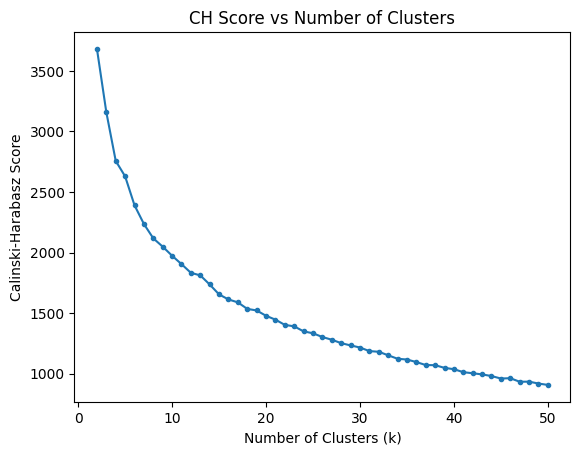

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

feature_columns = [c for c in df.columns if c.startswith("MFCCs")]
label_columns = ["Family", "Genus", "Species"]

x_all = df[feature_columns]
y_all = df[label_columns]
ch_scores = []

for k in range(2, 51):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_ids = model.fit_predict(x_all)
    score = calinski_harabasz_score(x_all, cluster_ids)
    ch_scores.append((k, score))

best_k, best_ch_score = max(ch_scores, key=lambda results: results[1])

print("Best k:", best_k)
print("Best CH Score:", round(best_ch_score, 4))

ks, scores = zip(*ch_scores)
plt.plot(ks, scores, marker='.')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("CH Score vs Number of Clusters")
plt.show()

### 2(b) In each cluster, determine which family is the majority by reading the true labels. Repeat for genus and species.

In [13]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
clusters = kmeans.fit_predict(x_all)
majority_rows = []

for cluster_id in sorted(set(clusters)):
    members = clusters == cluster_id
    row = {
        "Cluster": cluster_id,
        "Number of Observations": int(members.sum())
    }

    for label in label_columns:
        row[label] = y_all.loc[members, label].mode().iloc[0]
    
    majority_rows.append(row)

majority_labels = pd.DataFrame(majority_rows)
display(majority_labels)

,Cluster,Number of Observations,Family,Genus,Species
0,0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


### 2(c) Now for each cluster you have a majority label triplet (family, genus, species). Calculate the average Hamming distance, Hamming score, and Hamming loss between the true labels and the labels assigned by clusters.

In [16]:
import numpy as np

hamming_distances = []
hamming_scores = []
hamming_losses = []

for seed in range(50):
    model = KMeans(n_clusters=best_k, n_init=10, random_state=seed)
    cluster_ids = model.fit_predict(x_all)

    predicted_labels = pd.DataFrame(
        index=range(len(y_all)),
        columns=label_columns,
        dtype=object
    )

    for cluster_id in sorted(set(cluster_ids)):
        members = cluster_ids == cluster_id

        for label in label_columns:
            majority_label = y_all.loc[members, label].mode().iloc[0]
            predicted_labels.loc[members, label] = majority_label

    mismatches = y_all.to_numpy() != predicted_labels.to_numpy()
    distance = mismatches.sum(axis=1).mean()
    loss = mismatches.mean()
    score = 1 - loss

    hamming_distances.append(distance)
    hamming_losses.append(loss)
    hamming_scores.append(score)

print("Mean Hamming Distance:", round(np.mean(hamming_distances), 4))
print("Hamming Distance Standard Deviation:",
      round(np.std(hamming_distances, ddof=1), 4))
print("Mean Hamming Score:", round(np.mean(hamming_scores), 4))
print("Mean Hamming Loss:", round(np.mean(hamming_losses), 4))

Mean Hamming Distance: 0.8956
Hamming Distance Standard Deviation: 0.0
Mean Hamming Score: 0.7015
Mean Hamming Loss: 0.2985


**Answer:** The CH score picked 2 clusters. I ran k-means 50 times and gave each observation the most common labels in its cluster.

The average Hamming distance was .8956 with a standard deviation of .00. The Hamming score was .7015 and the Hamming loss was .2985. This means about 70.15% of the individual labels were correct and 29.85% were wrong.

## 3. ISLR 12.6.2